In [1]:
import numpy as np
import scipy as sp
import sympy as smp
import matplotlib.pyplot as plt
import random

import qiskit

import sys
sys.path.insert(0, '../../')

import oasis_dla

In [2]:
vqls = oasis_dla.VQLS(qubits=1, cost='direct')

A = np.array([
    [1, 0],
    [0, 1]
])

b = (1/np.sqrt(2)) * np.array([
    [1],
    [1]
])

X = np.array([
    [0, 1],
    [1, 0]
])

Y = np.array([
    [0, -1j],
    [1j, 0]
])

Z = np.array([
    [1, 0],
    [0, -1]
])

# pauli_matrices = [np.eye(2), X, Y, Z]
# coeffs = [0.5 * np.trace(P @ A) for P in pauli_matrices]

# sum = np.zeros((2, 2), np.complex128)
# for i, p in enumerate(pauli_matrices):
#     sum += (coeffs[i] * p)
# sum

solution = vqls.solve(A, b, shots=10_000)

print(f"Quantum Soln: \n{solution.solution()}")
print(f"Classical Soln: \n{np.linalg.solve(A, b)}")

solution.get_probabilities()

Training time: 0.09889829996973276
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [ 5.323e-13]
     nit: 36
   maxcv: 0.0
    nfev: 16
Quantum Soln: 
[[0.70710678+0.j]
 [0.70710678+0.j]]
Classical Soln: 
[[0.70710678]
 [0.70710678]]


{'0': 0.4958, '1': 0.5042}

Training time: 0.09527390002040192
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: -2.220446049250313e-16
       x: [ 2.564e-13]
     nit: 36
   maxcv: 0.0
    nfev: 17
[{'1': 0.4998, '0': 0.5002}]
classical probabilities: [0.5 0.5]


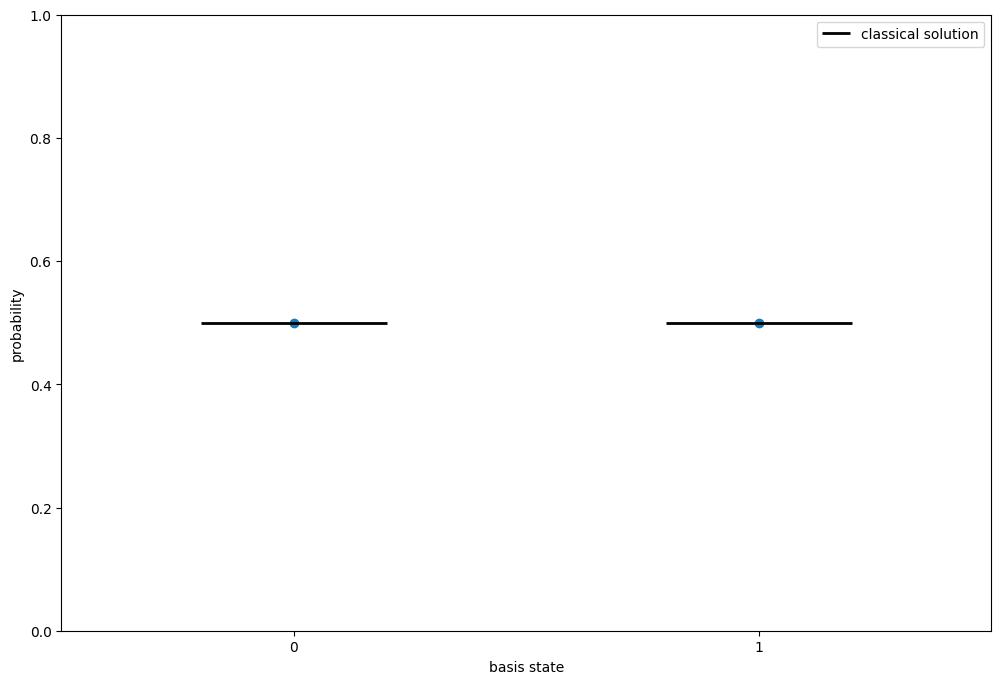

In [3]:
tests = 1

prob_list = []
for i in range(0, tests):
    res = vqls.solve(A, b)
    prob_list.append(res.get_probabilities())

print(prob_list)

# classical solution -> probabilities |x_i|^2 / ||x||^2
x_classical = np.linalg.solve(A, b).reshape(-1)
p_classical = np.abs(x_classical)**2 / np.sum(np.abs(x_classical)**2)
print(f"classical probabilities: {p_classical}")

fig, ax = plt.subplots(figsize=(12, 8))
# short horizontal line centered on each basis state at its classical probability
ax.hlines(p_classical, [-0.2, 0.8], [0.2, 1.2], colors="black", linewidth=2, label="classical solution")

for probs in prob_list:
    p = [probs.get("0", 0), probs.get("1", 0)]
    ax.scatter([0, 1], p)

ax.set_xticks([0, 1])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 1)
ax.set_xlabel("basis state")
ax.set_ylabel("probability")
ax.legend()
plt.show()

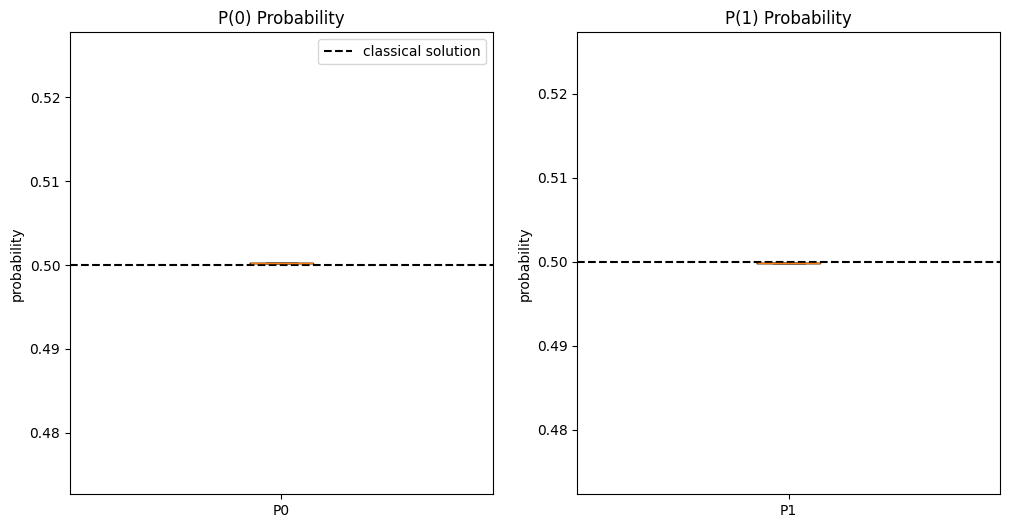

In [4]:
P0s = [probs.get("0", 0) for probs in prob_list]
P1s = [probs.get("1", 0) for probs in prob_list]

# separate panel
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, data, p_true, label in zip(axes, [P0s, P1s], p_classical, ["P0", "P1"]):
    ax.boxplot(data)
    ax.axhline(p_true, color="black", linestyle="--", linewidth=1.5, label="classical solution")
    ax.set_xticks([1])
    ax.set_xticklabels([label])
    ax.set_ylabel("probability")

axes[0].legend()
# plt.tight_layout()
axes[0].set_title("P(0) Probability")
axes[1].set_title("P(1) Probability")
plt.show()

# testing 1 qubit vqls on a suite of real and then complex matrices

In [5]:
random_c = lambda: random.random() + 1j * random.random()
random_r = random.random

A = np.array([
    [random_c(), random_c()],
    [random_c(), random_c()]
])
b = 1/np.sqrt(2) * np.array([
    [1],
    [1]
])

print(A)
qres = vqls.solve(A, b).solution()#.reshape(-1, 1)
cres = np.linalg.solve(A,b)
print(f"Quantum Solution: \n{qres}\n")
print(f"Classical Solution: \n{cres}\n")

# difference as a metric of accuracy
print(f"Accuracy: {vqls.compute_accuracy(qres, cres)*100:.3f}%")

[[0.8769911 +0.74780944j 0.83838542+0.97421818j]
 [0.5920671 +0.3610841j  0.89378866+0.0397946j ]]
Training time: 0.19555330002913252
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.05772995576604101
       x: [-1.950e+00]
     nit: 41
   maxcv: 0.0
    nfev: 25
Quantum Solution: 
[[ 0.73329111-0.58984827j]
 [-0.14072393+0.1131962j ]]

Classical Solution: 
[[0.34862074-0.98328685j]
 [0.18532116+0.50226147j]]

Accuracy: 25.137%


In [6]:
# def res_diff(x, y):
#     return 1 - np.linalg.norm(x-y)

# def test_vqls(b=None, shots=30):
#     Ai = [ # random data set of matrices
#         np.array([
#             [1, random_c()],
#             [random_c(), random_c()]
#         ]) for _ in range(shots)
#     ]

#     if b is None:
#         b = 1/np.sqrt(2) * np.array([
#             [1],
#             [1]
#         ])

#     accuracies = []
#     for A in Ai:
#         # print(b)
#         q_soln = vqls.solve(A, b).solution()
#         c_soln = np.linalg.solve(A, b)
#         # print(f"Quantum Solution: \n{q_soln}\n")
#         # print(f"Classical Solution: \n{c_soln}\n")

#         diff = res_diff(q_soln, c_soln)
#         # print(f"Accuracy: {diff}")
#         accuracies.append(diff)

#     # print(accuracies)

#     return accuracies

# accuracies = test_vqls()
# avg_diff = sum(accuracies) / len(accuracies)

# print(f"Average Quantum Solution Accuracy: {avg_diff*100:.2f}%")

In [7]:
# avg_diff, accuracies

In [8]:
# plt.plot(np.linspace(0, len(accuracies), 1), accuracies)
# plt.axhline(avg_diff, color='black', linestyle='--', label="Average")
# plt.ylabel("Accuracy")
# plt.xlabel("Test # (random matrix)")
# plt.title("Constant Top Right Entry")
# plt.legend()

In [11]:
vqls_ry = oasis_dla.VQLS(qubits=1, ansatz_type=0, cost='direct')
vqls_rz = oasis_dla.VQLS(qubits=1, ansatz_type=1, cost='direct')

data = vqls.generate_dataset(random_entries=[1+1j, 2+0j, 3+1j, 4+0j], shots=100)
print(data[:3])

# 1 param ansatz ry h
accuracies_ry, t_times_ry = vqls_ry.accuracy_test(data)
accuracies_rz, t_times_rz = vqls_rz.accuracy_test(data)

[array([[0.98810733+0.42803144j, 0.4049517 +0.j        ],
       [0.42337781+0.50423338j, 0.71746725+0.j        ]]), array([[0.96021379+0.61797231j, 0.96157991+0.j        ],
       [0.52113135+0.55416968j, 0.52812901+0.j        ]]), array([[0.16194868+0.48257295j, 0.44897568+0.j        ],
       [0.52913354+0.54359847j, 0.95233689+0.j        ]])]
Training time: 0.12680969998473302
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.0004544826014196701
       x: [ 5.683e-01]
     nit: 37
   maxcv: 0.0
    nfev: 16
0.9440105754358544
Training time: 0.1187070999876596
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.0029524395040207985
       x: [-3.155e+00]
     nit: 43
   maxcv: 0.0
    nfev: 23
0.5496969921251065
Training time: 0.07373849995201454
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.0031852320034

Average Accuracy = -0.6483507438492228
Average Accuracy = 0.9999970019622453


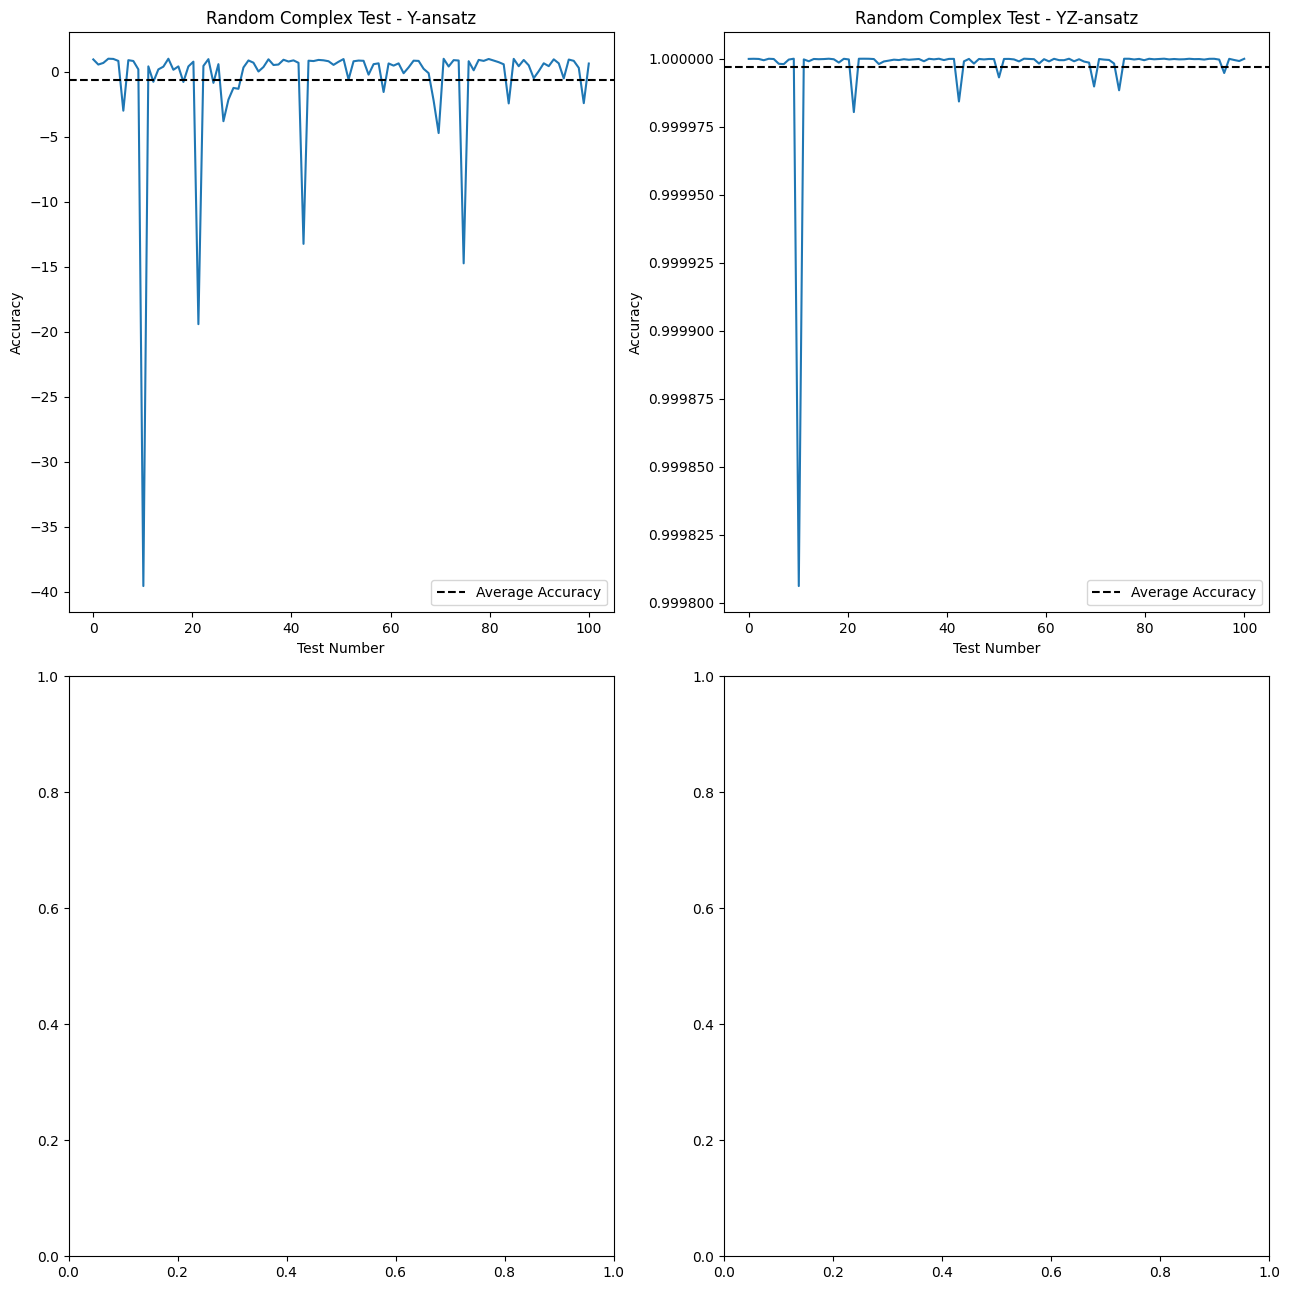

In [ ]:
# 2 param ansatz rz ry h
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(13, 13), sharey=False)
ax_0 = vqls_ry.plot_tests(accuracies_ry, title="Random Complex Test - Y-ansatz", ax=axes[0, 0])
ax_1 = vqls_rz.plot_tests(accuracies_rz, title="Random Complex Test - YZ-ansatz", ax=axes[0, 1])

plt.tight_layout()
plt.show()

t_times_ry